# Fraud Detection: EDA

## 1. Setup
Imports, paths, and constants. Everything configurable lives in one cell.

In [1]:
import math
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DATA_PATH = pathlib.Path.cwd().parent / "data/ieee-fraud-detection"

ID_COL = "TransactionID"
TARGET = "isFraud"
CORE_COLUMNS = [
    "TransactionID",
    "isFraud",
    "TransactionDT",
    "TransactionAmt",
    "ProductCD",
    "card1",
    "card2",
    "card3",
    "card4",
    "card5",
    "card6",
    "addr1",
    "addr2",
    "dist1",
    "dist2",
    "P_emaildomain",
    "R_emaildomain",
]

pd.set_option("display.max_colwidth", None)
plt.style.use("ggplot")

### Helpers
Each function does one job and takes a DataFrame as input (no hidden globals).
`plot_grid` only handles layout. The plot itself is passed in as `plot_fn`, so a new chart type needs no change to existing code.

In [7]:
def numeric_cols(df):
    return df.select_dtypes(include="number").columns.tolist()


def categorical_cols(df):
    return df.select_dtypes(include=["object", "category", "string"]).columns.tolist()


def missing_report(df):
    count = df.isna().sum()
    return (
        pd.DataFrame({"missing": count, "missing_%": (count / len(df) * 100).round(2)})
        .sort_values("missing_%", ascending=False)
    )


def skew_kurt_report(df):
    cols = numeric_cols(df)
    report = pd.DataFrame({"skew": df[cols].skew(), "kurtosis": df[cols].kurt()})
    return report.sort_values("skew", key=abs, ascending=False).round(2)


def inconsistent_text(df):
    """Values with stray spaces or mixed case, per categorical column."""
    found = {}
    for col in categorical_cols(df):
        s = df[col].dropna().astype(str)
        bad = s[s.ne(s.str.strip()) | s.ne(s.str.strip().str.lower())].unique()
        if len(bad):
            found[col] = bad
    return found


def plot_grid(columns, plot_fn, ncols=3, cell_size=(6, 4), title=None):
    """Draw one subplot per column. plot_fn(column, ax) does the actual plot."""
    nrows = math.ceil(len(columns) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(cell_size[0] * ncols, cell_size[1] * nrows), squeeze=False
    )
    flat = axes.flatten()
    for col, ax in zip(columns, flat):
        plot_fn(col, ax)
    for ax in flat[len(columns):]:
        ax.set_visible(False)
    if title:
        fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

## 2. Load Data
Load the CSV, keep the core columns, and separate the target from the features.
The test set is not loaded: EDA should only look at train.

In [2]:
raw_df = pd.read_csv(DATA_PATH / "train_transaction.csv")
df = raw_df[CORE_COLUMNS].copy()

y = df[TARGET]
X = df.drop(columns=[ID_COL, TARGET])

print(f"raw: {raw_df.shape} | core: {df.shape}")

raw: (590540, 394) | core: (590540, 17)


In [3]:
df.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,19.0,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,NaN,NaN,gmail.com,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,287.0,NaN,outlook.com,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,NaN,NaN,yahoo.com,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,NaN,NaN,gmail.com,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Data columns (total 17 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   TransactionID   590540 non-null  int64  
 1   isFraud         590540 non-null  int64  
 2   TransactionDT   590540 non-null  int64  
 3   TransactionAmt  590540 non-null  float64
 4   ProductCD       590540 non-null  str    
 5   card1           590540 non-null  int64  
 6   card2           581607 non-null  float64
 7   card3           588975 non-null  float64
 8   card4           588963 non-null  str    
 9   card5           586281 non-null  float64
 10  card6           588969 non-null  str    
 11  addr1           524834 non-null  float64
 12  addr2           524834 non-null  float64
 13  dist1           238269 non-null  float64
 14  dist2           37627 non-null   float64
 15  P_emaildomain   496084 non-null  str    
 16  R_emaildomain   137291 non-null  str    
dtypes: float64(8), int64(

In [5]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
TransactionDT,590540.0,7.372311e+06,4.617224e+06,86400.000,3027057.750,7306527.500,11246620.0,1.581113e+07
TransactionAmt,590540.0,1.350272e+02,2.391625e+02,0.251,43.321,68.769,125.0,3.193739e+04
card1,590540.0,9.898735e+03,4.901170e+03,1000.000,6019.000,9678.000,14184.0,1.839600e+04
card2,581607.0,3.625555e+02,1.577932e+02,100.000,214.000,361.000,512.0,6.000000e+02
card3,588975.0,1.531949e+02,1.133644e+01,100.000,150.000,150.000,150.0,2.310000e+02
card5,586281.0,1.992789e+02,4.124445e+01,100.000,166.000,226.000,226.0,2.370000e+02
addr1,524834.0,2.907338e+02,1.017411e+02,100.000,204.000,299.000,330.0,5.400000e+02
addr2,524834.0,8.680063e+01,2.690623e+00,10.000,87.000,87.000,87.0,1.020000e+02
dist1,238269.0,1.185022e+02,3.718720e+02,0.000,3.000,8.000,24.0,1.028600e+04
dist2,37627.0,2.318554e+02,5.290535e+02,0.000,7.000,37.000,206.0,1.162300e+04


## 3. Data Quality
### 3.1 Missing values
Sorted by percentage. Columns with heavy missingness are candidates for an `isnull` flag instead of imputation.

In [8]:
missing_report(X)

,missing,missing_%
dist2,552913,93.63
R_emaildomain,453249,76.75
dist1,352271,59.65
P_emaildomain,94456,15.99
addr1,65706,11.13
addr2,65706,11.13
card2,8933,1.51
card5,4259,0.72
card3,1565,0.27
card4,1577,0.27


### 3.2 Duplicates
`TransactionID` is unique per row, so full-row duplicates are checked on features only.

In [9]:
print(f"duplicate feature rows: {X.duplicated().sum()}")
print(f"duplicate TransactionID: {df[ID_COL].duplicated().sum()}")

duplicate feature rows: 62
duplicate TransactionID: 0


### 3.3 Inconsistent text
Looks for stray spaces and mixed case in categorical columns. An empty result means the text is clean.

In [10]:
inconsistent_text(X)

{'ProductCD': <ArrowStringArray>
 ['W', 'H', 'C', 'S', 'R']
 Length: 5, dtype: str}

## 4. Target Distribution
Fraud is rare, so accuracy is misleading. ROC-AUC and PR-AUC are the metrics to use, and the split must be stratified or time-based.

isFraud
0    96.5
1     3.5


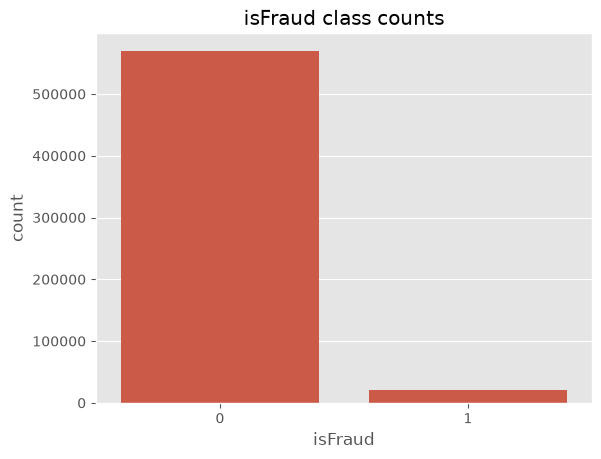

In [11]:
rate = y.value_counts(normalize=True).mul(100).round(2)
print(rate.to_string())

sns.countplot(x=y)
plt.title("isFraud class counts")
plt.show()

## 5. Univariate Analysis
### 5.1 Numerical: distribution and outliers
Histogram (with KDE) on the left, boxplot on the right for each feature. Right-skewed features such as `TransactionAmt` are candidates for a log transform.

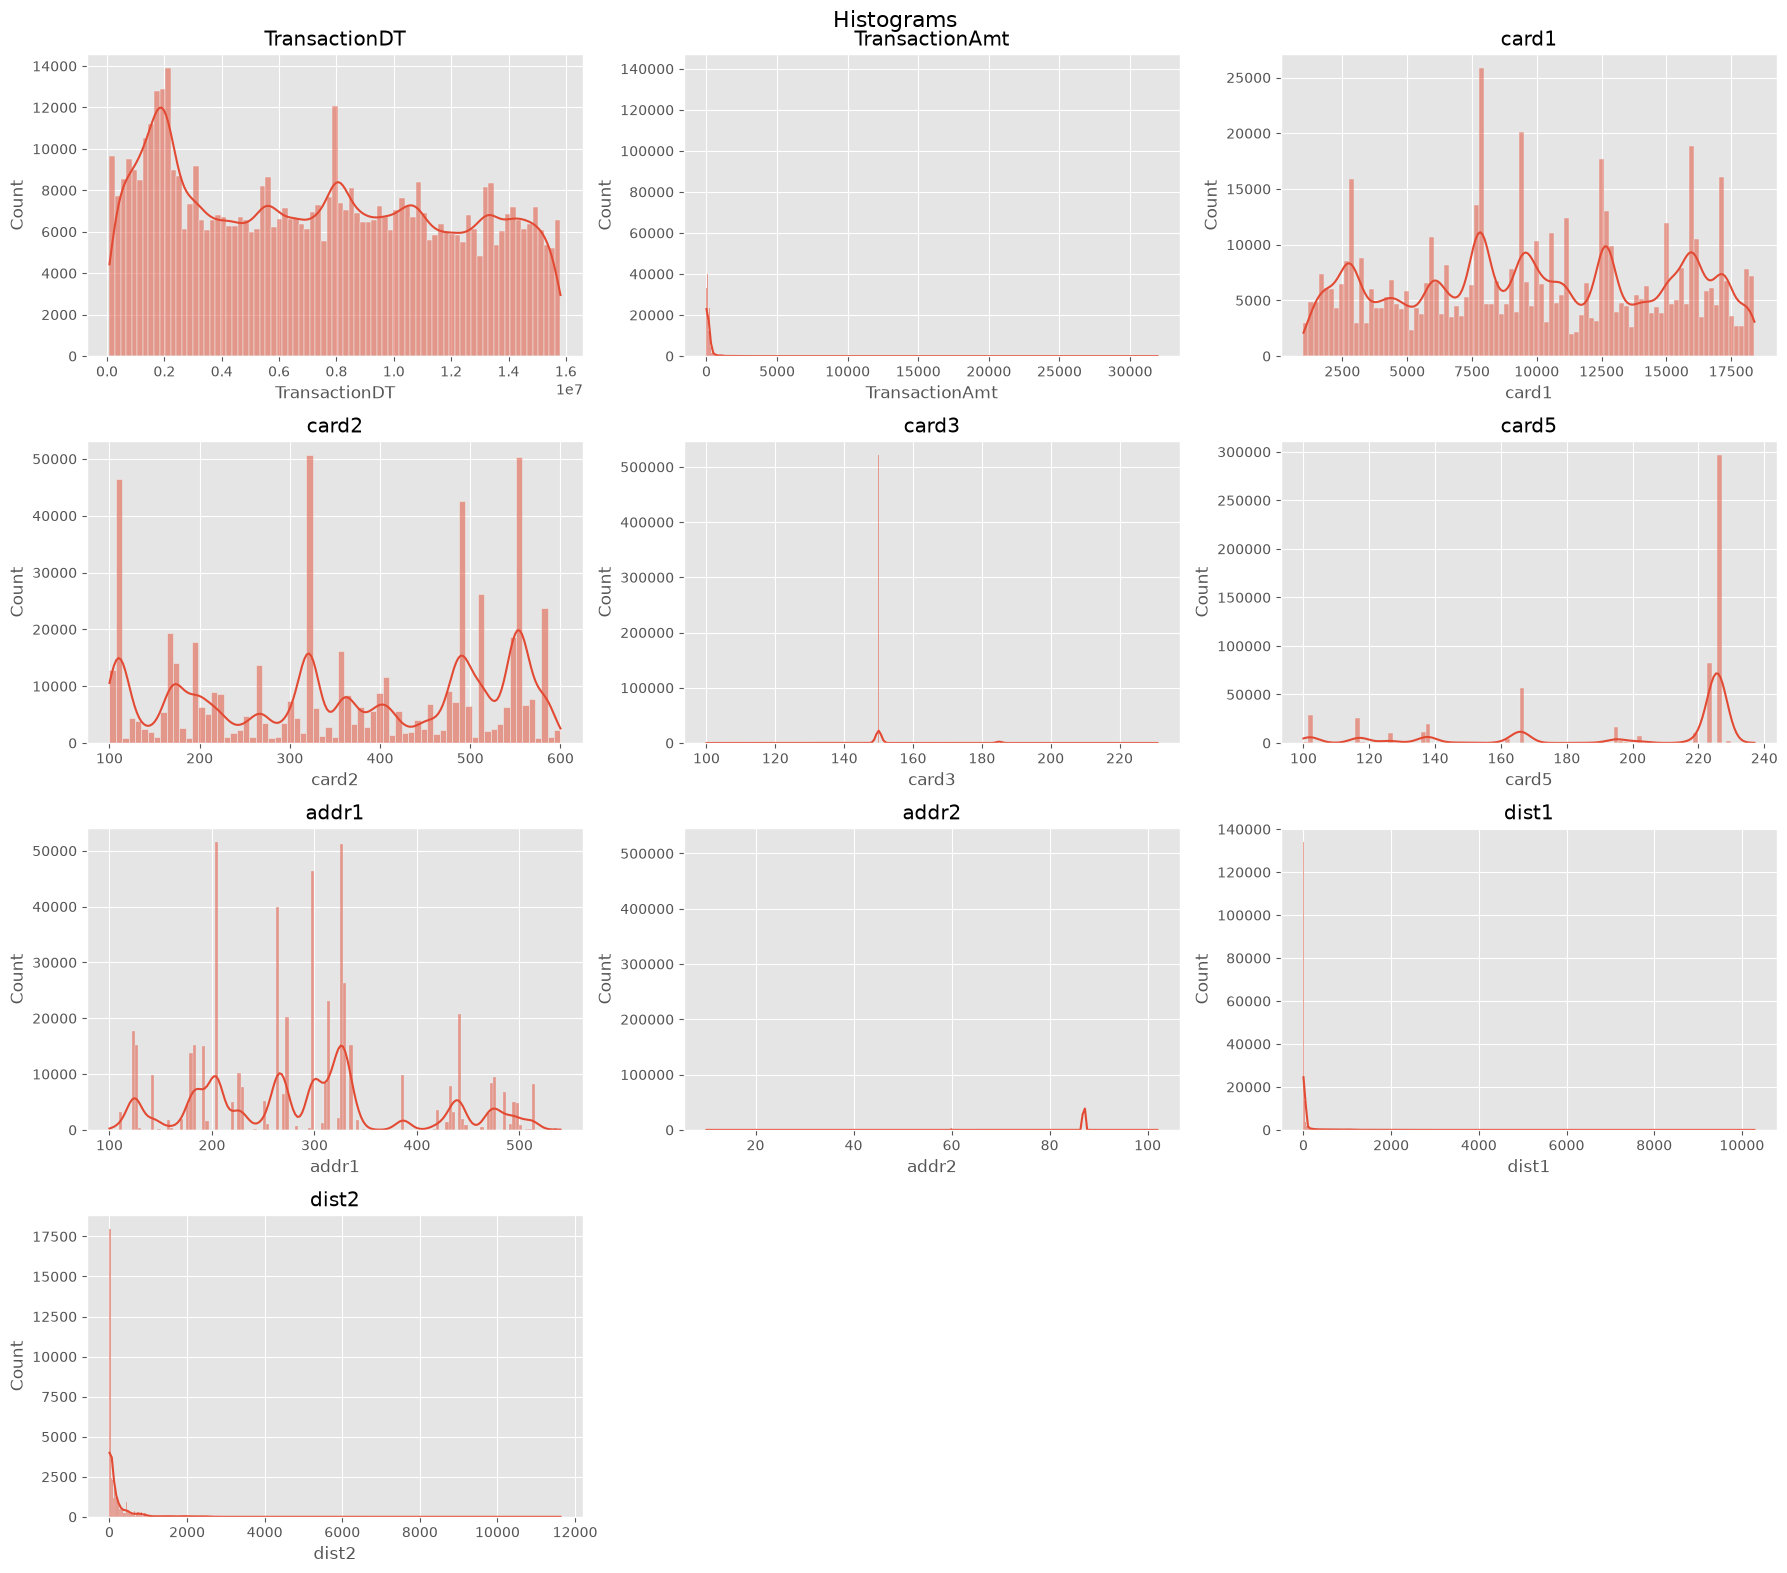

In [12]:
num = numeric_cols(X)

def hist(col, ax):
    sns.histplot(X[col], kde=X[col].nunique() > 1, ax=ax)
    ax.set_title(col)

plot_grid(num, hist, title="Histograms")

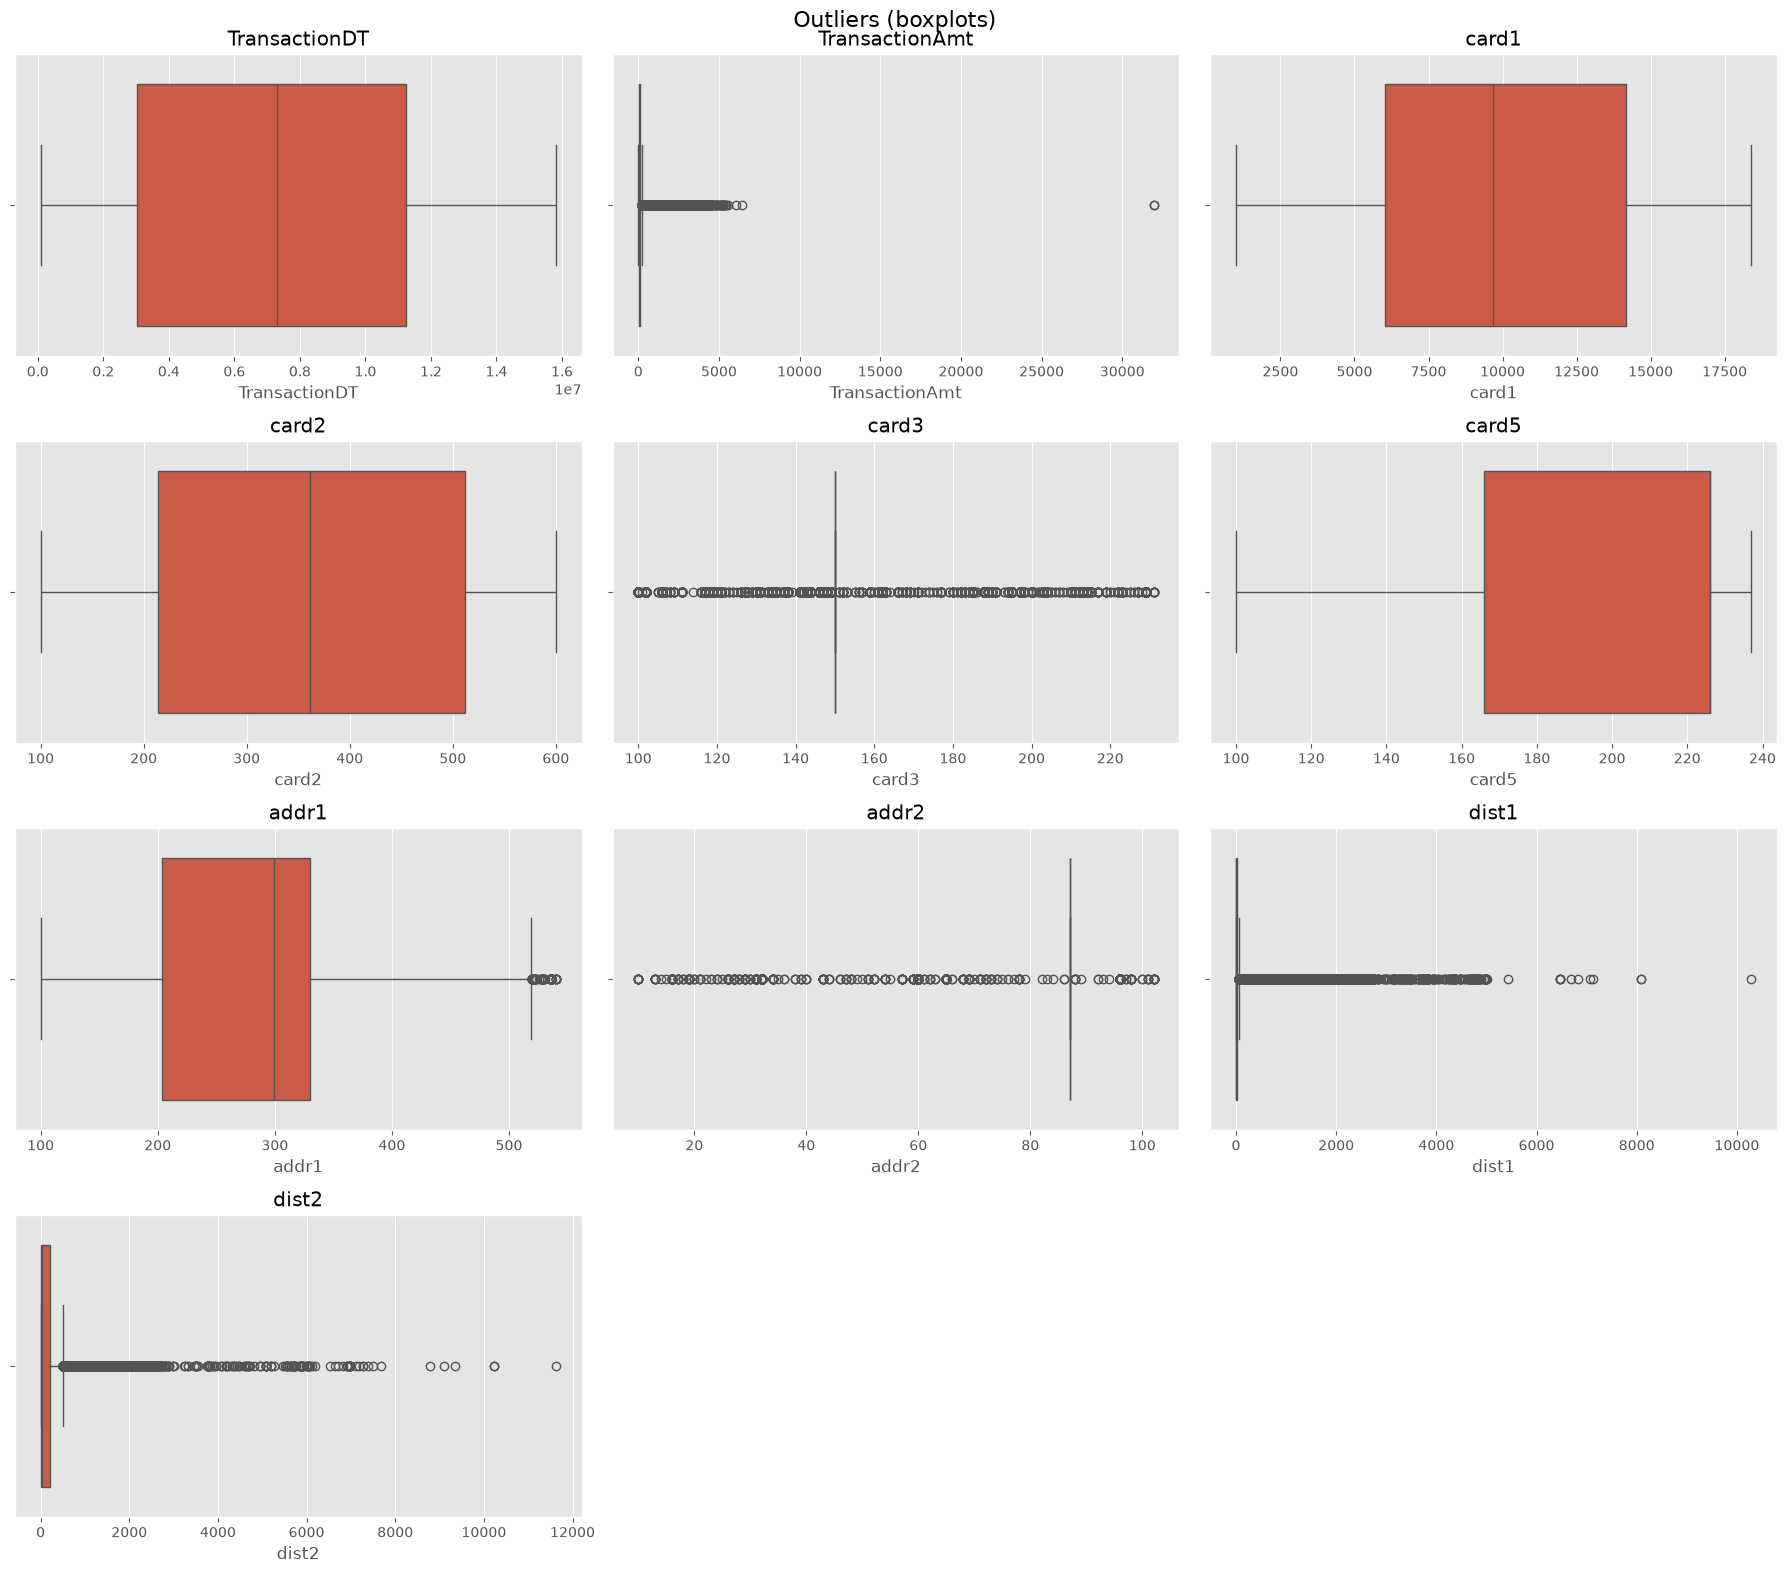

In [13]:
def box(col, ax):
    sns.boxplot(x=X[col], ax=ax)
    ax.set_title(col)

plot_grid(num, box, title="Outliers (boxplots)")

### 5.2 Numerical: skewness and kurtosis
`|skew| > 1` means highly skewed. Large positive kurtosis means heavy tails (many outliers).

In [14]:
skew_kurt_report(X)

,skew,kurtosis
addr2,-14.50,256.78
TransactionAmt,14.37,1123.96
dist2,5.97,58.68
dist1,5.11,36.80
card3,2.02,6.32
card5,-1.22,-0.05
addr1,0.37,-0.50
card2,-0.20,-1.33
TransactionDT,0.13,-1.23
card1,-0.04,-1.14


### 5.3 Categorical: value counts
Top 15 categories per column, with `NaN` shown as its own bar. High cardinality here (for example email domains) points to grouping or frequency encoding.

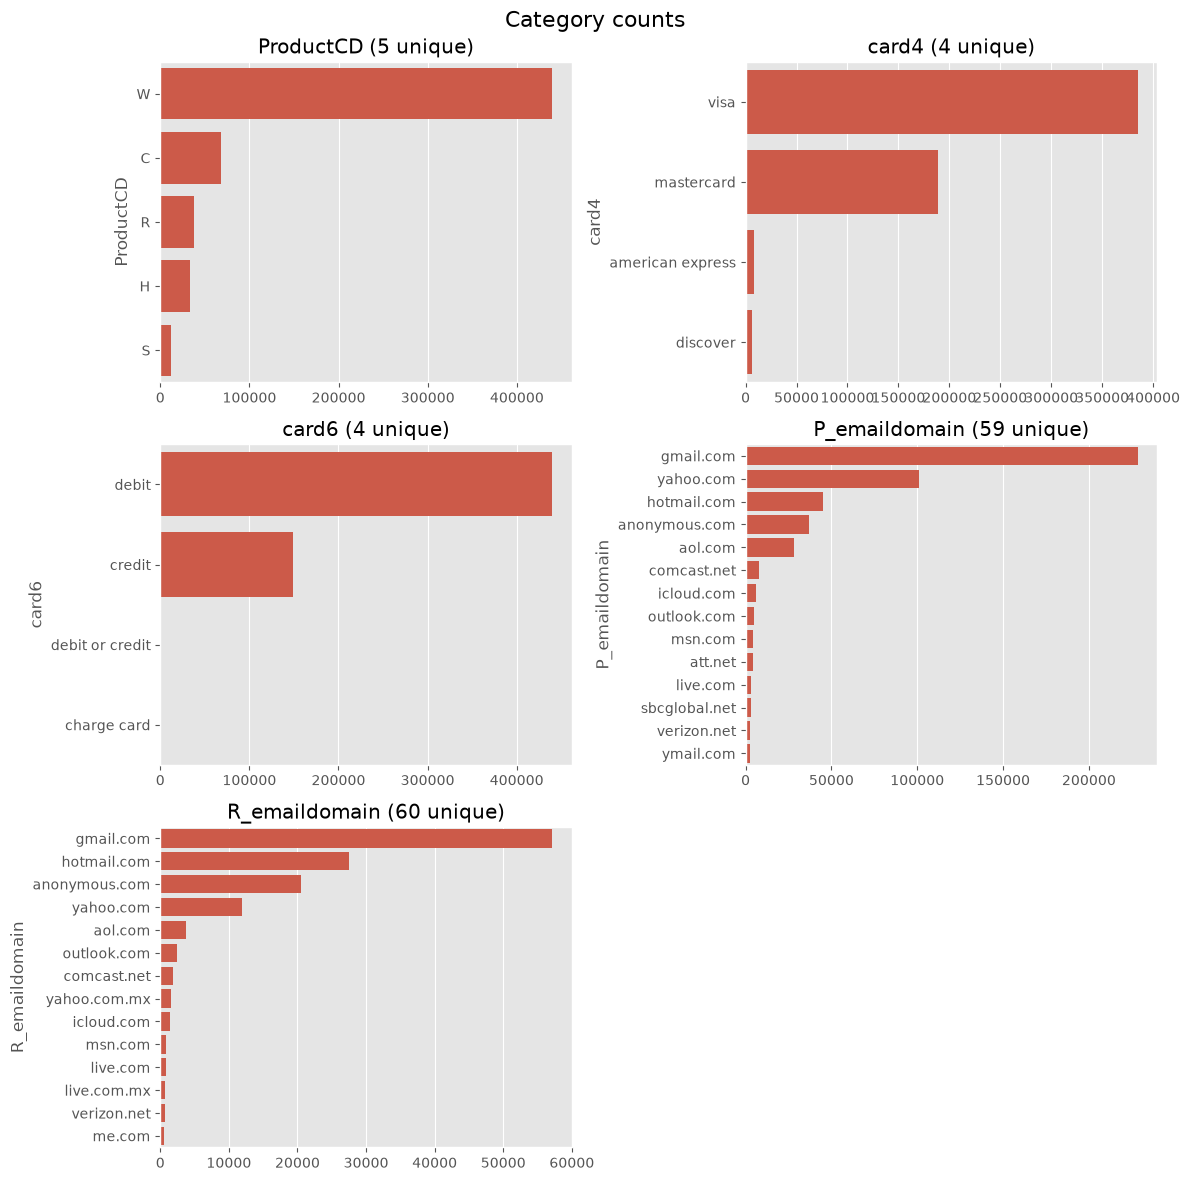

In [15]:
cat = categorical_cols(X)

def counts(col, ax):
    top = X[col].value_counts(dropna=False).head(15)
    sns.barplot(x=top.values, y=top.index.astype(str), ax=ax)
    ax.set_title(f"{col} ({X[col].nunique()} unique)")

plot_grid(cat, counts, ncols=2, title="Category counts")

## 6. Bivariate Analysis
### 6.1 Numerical vs. target
Compares each feature for fraud (1) and non-fraud (0). Features whose boxes differ are more useful.

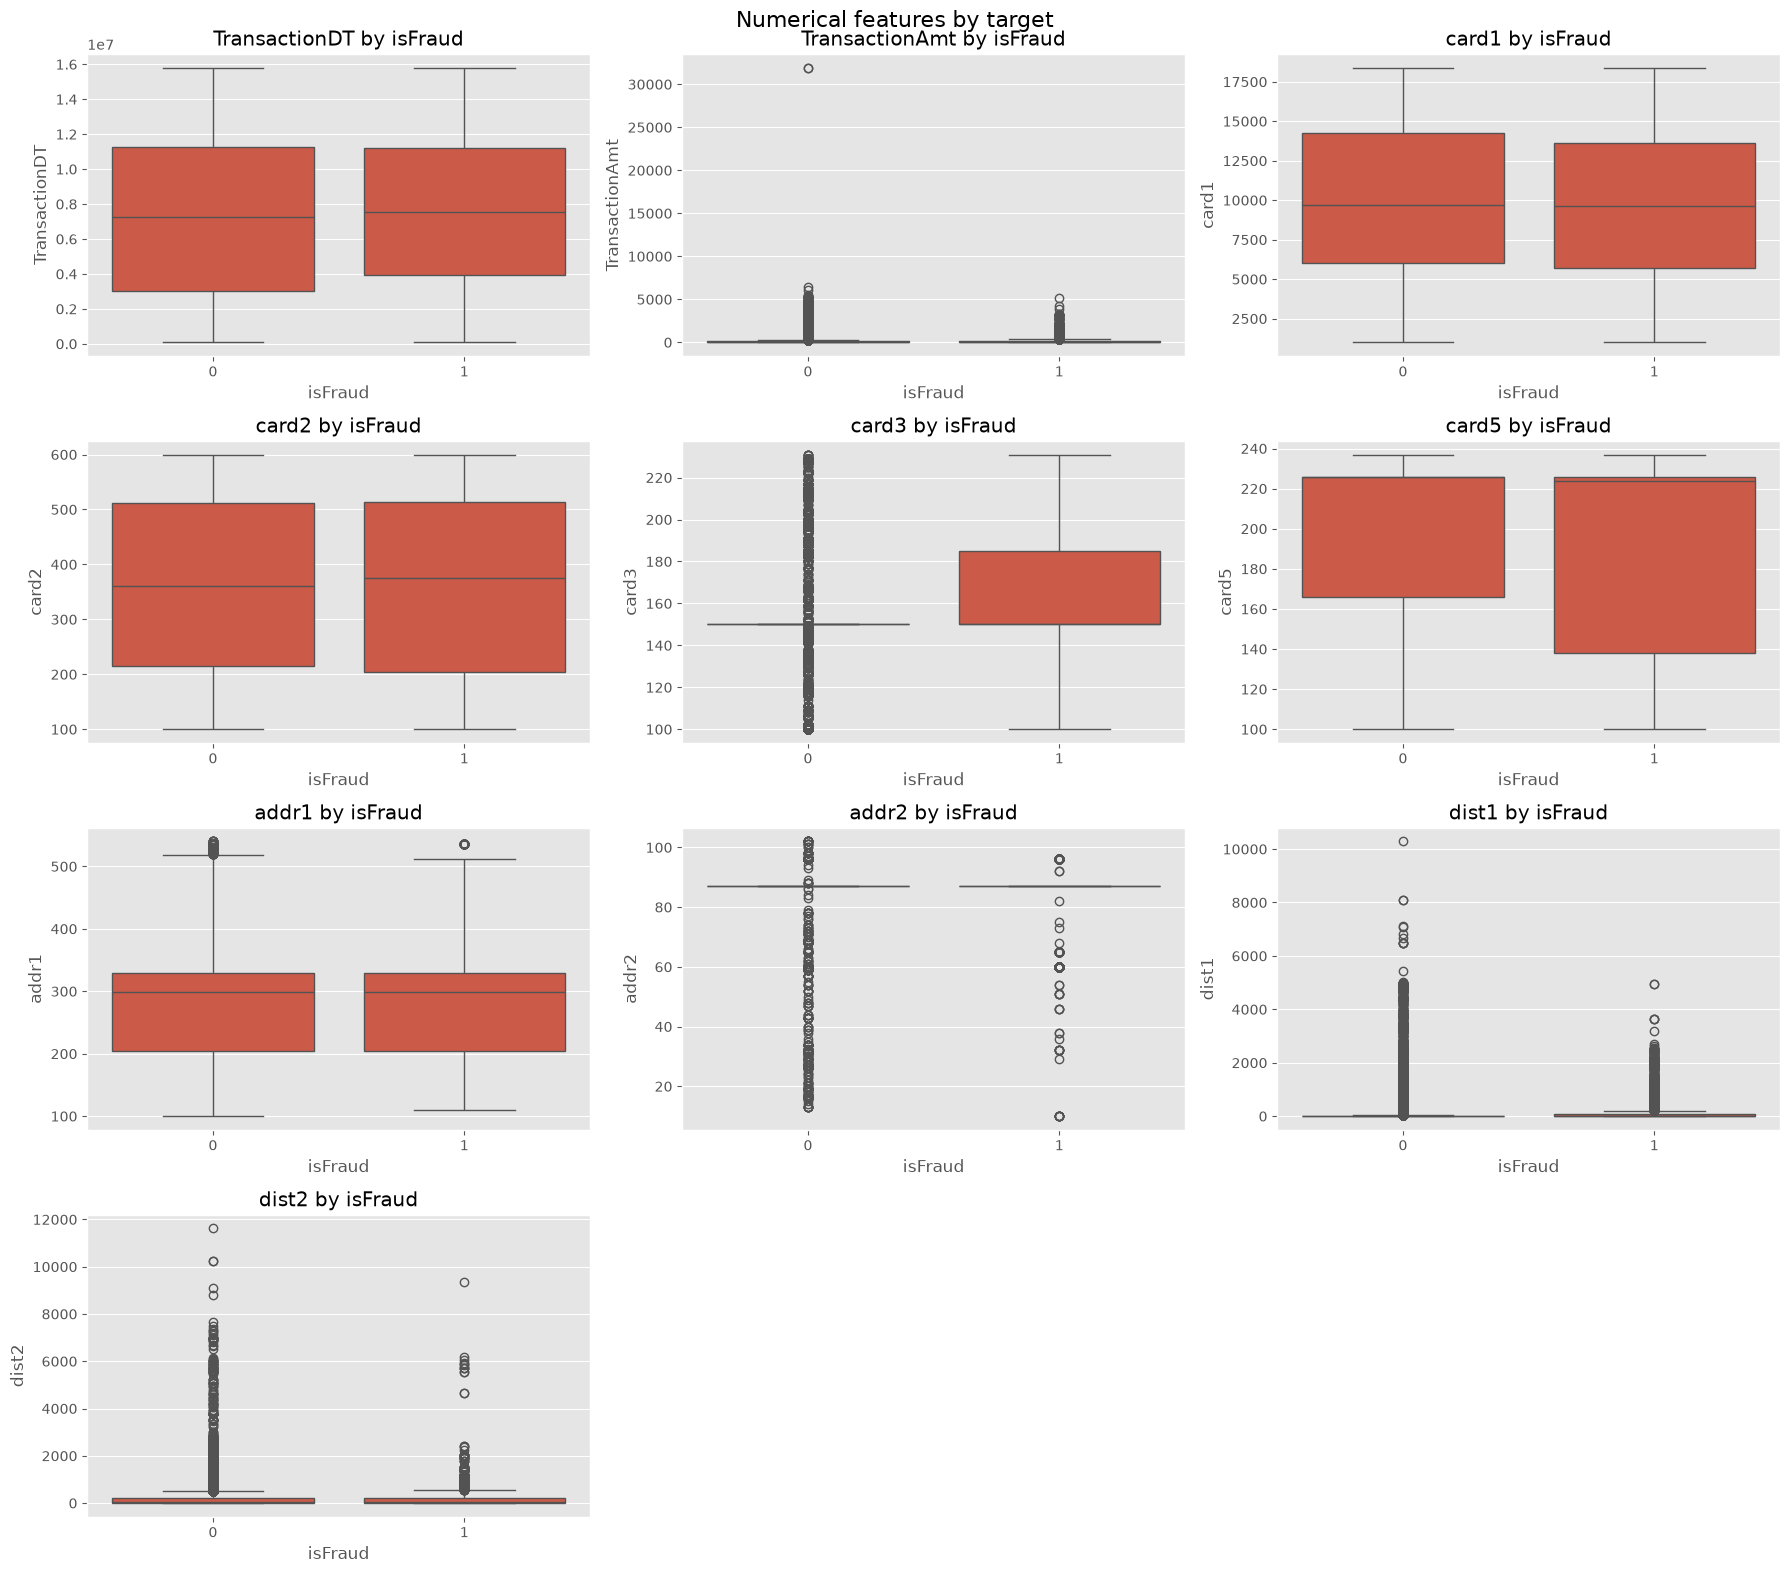

In [16]:
def box_by_target(col, ax):
    sns.boxplot(x=y, y=X[col], ax=ax)
    ax.set_title(f"{col} by {TARGET}")

plot_grid(num, box_by_target, title="Numerical features by target")

### 6.2 Categorical vs. target
Fraud **rate** per category (not raw counts, which are dominated by the majority class). The dashed line is the overall fraud rate, so bars above it are riskier than average.

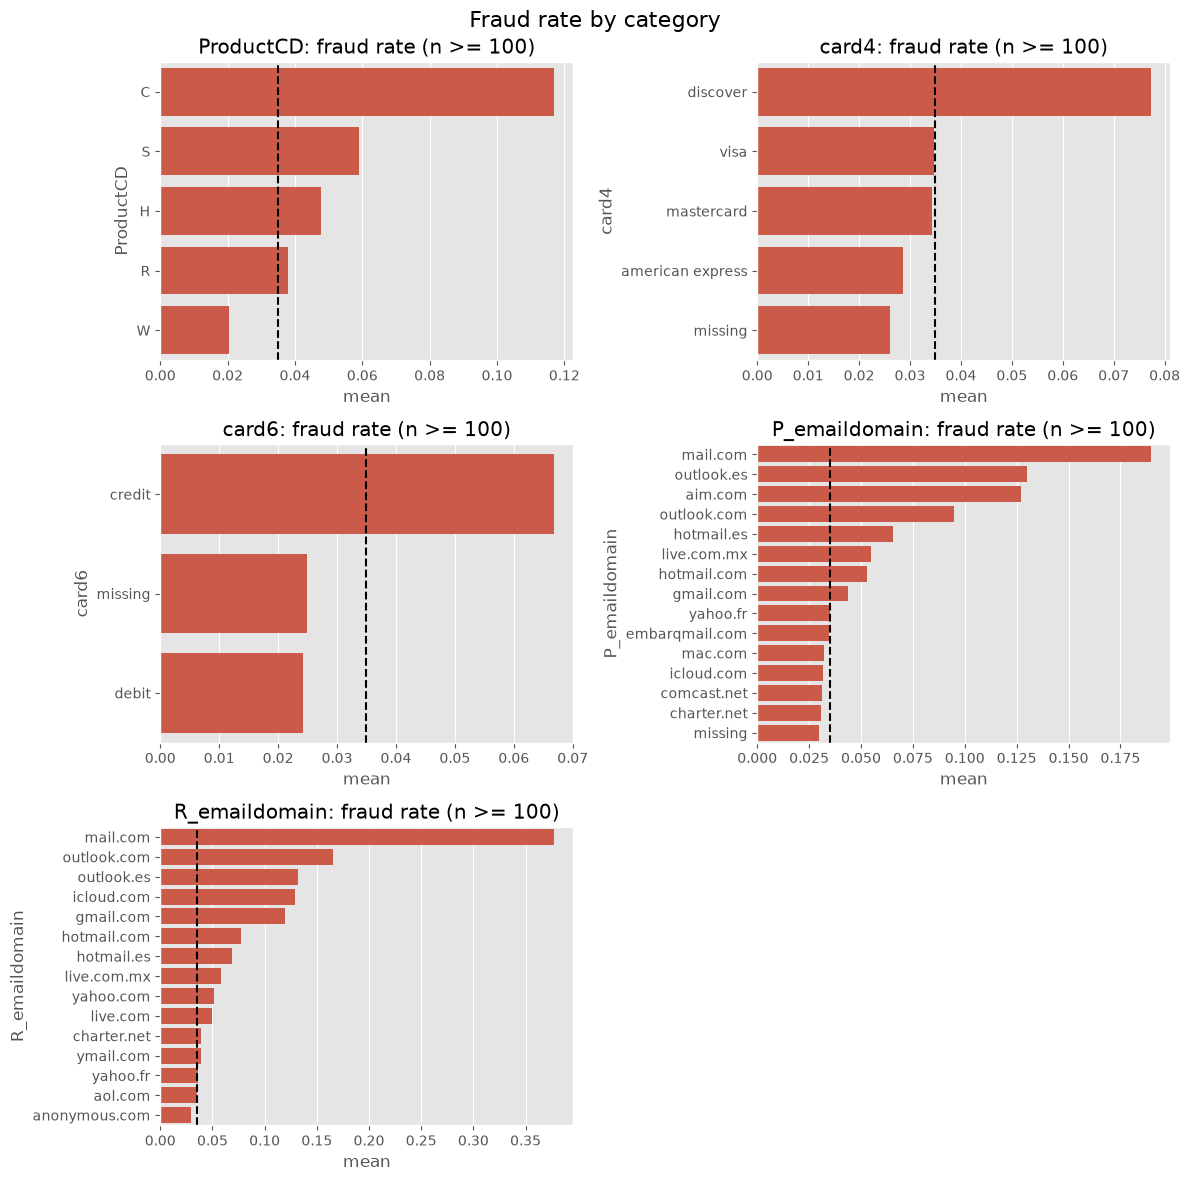

In [17]:
overall = y.mean()

def fraud_rate(col, ax):
    rate = (
        y.groupby(X[col].fillna("missing")).agg(["mean", "size"])
        .query("size >= 100")
        .sort_values("mean", ascending=False)
        .head(15)
    )
    sns.barplot(x=rate["mean"], y=rate.index.astype(str), ax=ax)
    ax.axvline(overall, color="black", linestyle="--")
    ax.set_title(f"{col}: fraud rate (n >= 100)")

plot_grid(cat, fraud_rate, ncols=2, title="Fraud rate by category")

## 7. Correlation
Pearson correlation between numeric features. Pairs with `|corr| > 0.9` are redundant, so keep one of each.

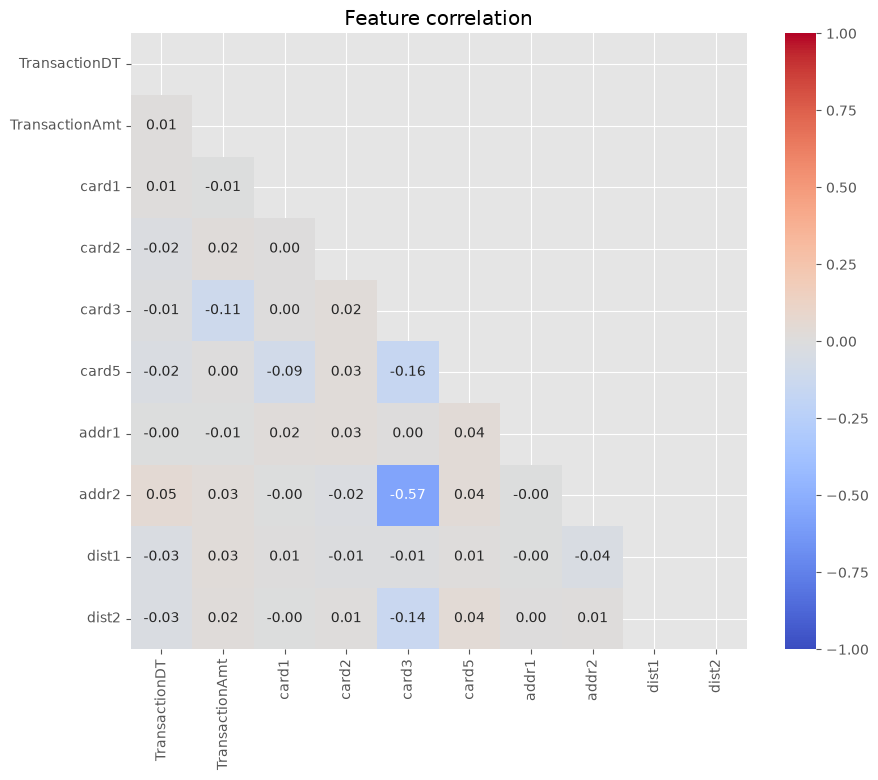

In [18]:
corr = X[num].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr, mask=np.triu(np.ones_like(corr, dtype=bool)),
    annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True,
)
plt.title("Feature correlation")
plt.show()

In [19]:
pairs = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).stack()
pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False)

Series([], dtype: float64)